# Week 1 EDA: Listing Remark Patterns

**Goal:** understand the structure and language of MLS listing remarks before building entity extraction, search, and compliance features.

**Data:**
- `data/processed/listing_sample.csv`: 1,000 random remarks from `rets_property` (seed 42, length > 50 chars)
- `data/processed/ngram_candidates.csv`: top 1/2/3-grams mined by `scripts/taxonomy_builder.py`
- `data/processed/taxonomy.json`: 218 terms across 8 categories

Run this notebook from the project root, or from `notebooks/` (the next cell handles both).

In [28]:
import json
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Work from the project root whether the notebook is opened from notebooks/ or the root
if Path.cwd().name == "notebooks":
    os.chdir("..")

DATA = Path("data/processed")
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.figsize"] = (9, 4)
print("Working directory:", Path.cwd())

Working directory: /Users/jacobkim/IDX_Exchange_Internship_Fall_2026/IDX-Exchange-NLP


##  Database overview
Row counts for the three source tables (requires the Docker MySQL container to be running).

In [29]:
try:
    import mysql.connector
    conn = mysql.connector.connect(host="127.0.0.1", port=3306, user="root",
                                   password="root", database="real_estate")
    cur = conn.cursor()
    counts = {}
    for t in ["rets_property", "rets_openhouse", "california_sold"]:
        cur.execute(f"SELECT COUNT(*) FROM {t}")
        counts[t] = cur.fetchone()[0]
    conn.close()
    display(pd.Series(counts, name="rows").to_frame())
except Exception as e:
    print("Database not reachable (start it with `docker compose start`):", e)

Database not reachable (start it with `docker compose start`): 2003 (HY000): Can't connect to MySQL server on '127.0.0.1:3306' (61)


## 2. Load the sample

In [30]:
df = pd.read_csv(DATA / "listing_sample.csv")
print(df.shape)
display(df.head())
display(df.isna().sum().rename("missing").to_frame())

(1000, 7)


,L_ListingID,L_Address,L_City,beds,baths,price,remarks
0,1190222255,39909 Via Castana,Murrieta,5.0,4.0,665000,"Picture yourself in this welcoming TURNKEY 5-bedroom, 4-bathroom CORNER home with 2,520 sq ft. Highlights that make ..."
1,1173177296,21999 Fallview,Sonora,4.0,3.0,385000,"Welcome to this extremely clean turn key home. This single story home shows like new, boasting 4 bedrooms, 3 full ba..."
2,1176554415,3391 Scarboro,Los Angeles,3.0,3.0,1400000,"Featuring 3 bedrooms, including 2 master suites, 3 full bathrooms, a large bonus room, a living room with dining are..."
3,1176005414,11063 Kibbins,Stanton,2.0,1.0,605000,Beautiful condo in the city of Stanton. This condo has shown up as a condo/town house as well in this area. This is ...
4,1179547557,60582 Silver Torch Circle,La Quinta,3.0,2.0,596000,"Stylish and sophisticated, the Monarch plan is ideally positioned on a private cul-de-sac, showcasing an oversized h..."


,missing
L_ListingID,0
L_Address,0
L_City,1
beds,4
baths,0
price,0
remarks,0


##  Remark length
How long are remarks? This affects summarization and embedding choices later.

,char_len,word_len
count,1000.0,1000.0
mean,1338.7,201.9
std,579.3,85.5
min,138.0,24.0
25%,953.8,145.0
50%,1273.0,191.0
75%,1692.0,255.0
max,3999.0,576.0


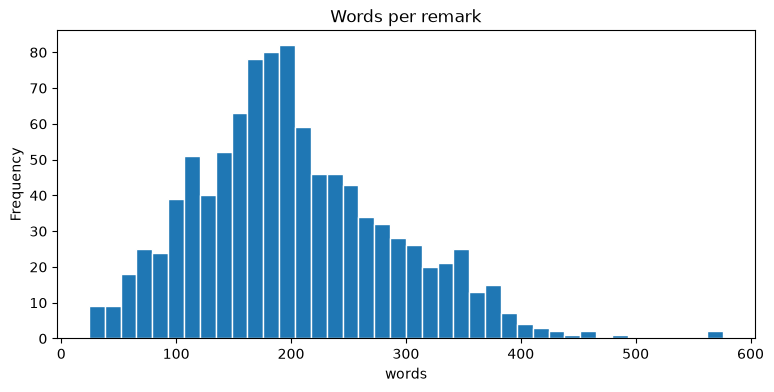

In [31]:
df["char_len"] = df["remarks"].str.len()
df["word_len"] = df["remarks"].str.split().str.len()
display(df[["char_len", "word_len"]].describe().round(1))

#Plot 
df["word_len"].plot.hist(bins=40, edgecolor="white")
plt.title("Words per remark")
plt.xlabel("words")
plt.show()

**Findings:**
- _TODO: typical length (median words), shortest/longest, any spike near a character limit?_

## Structured fields: beds, baths, price, city

,beds,baths,price
count,996.0,1000.0,1000.0
mean,3.3,2.8,1468937.5
std,1.3,1.5,2786175.3
min,0.0,0.0,45000.0
25%,2.0,2.0,538000.0
50%,3.0,3.0,815730.0
75%,4.0,3.0,1369750.0
max,11.0,16.0,48888000.0


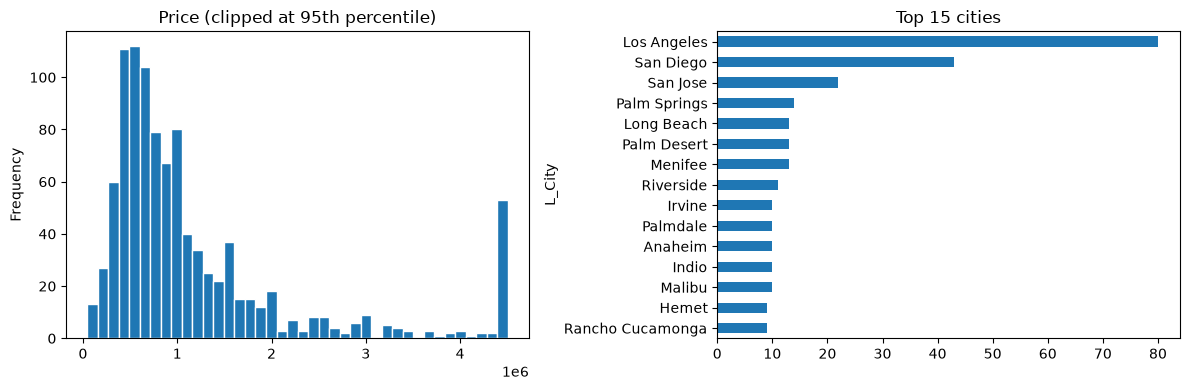

In [5]:
num = df[["beds", "baths", "price"]].apply(pd.to_numeric, errors="coerce")
display(num.describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
num["price"].clip(upper=num["price"].quantile(0.95)).plot.hist(bins=40, ax=axes[0], edgecolor="white")
axes[0].set_title("Price (clipped at 95th percentile)")
df["L_City"].value_counts().head(15).sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Top 15 cities")
plt.tight_layout()
plt.show()

**Findings:**
- _TODO: price range, most common bed counts, which cities dominate the sample?_

## Most common phrases (n-grams)

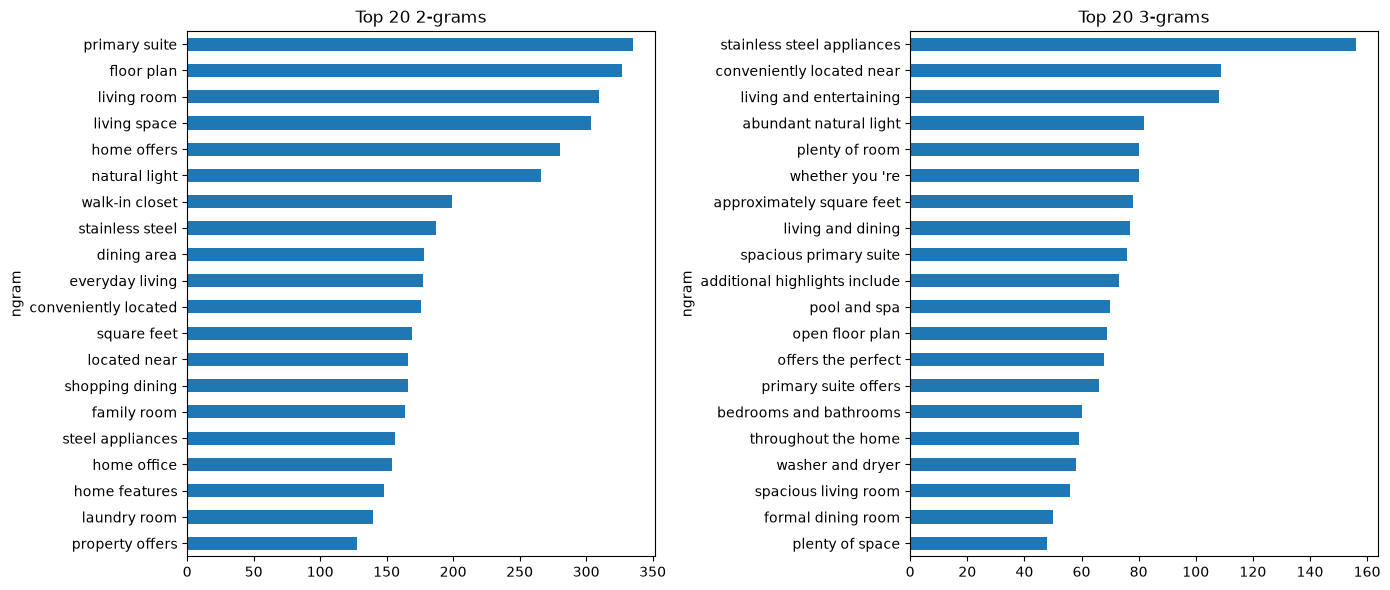

In [6]:
ng = pd.read_csv(DATA / "ngram_candidates.csv")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, n in zip(axes, [2, 3]):
    ng[ng.n == n].head(20).set_index("ngram")["count"].sort_values().plot.barh(ax=ax)
    ax.set_title(f"Top 20 {n}-grams")
plt.tight_layout()
plt.show()

**Findings:**
- _TODO: which phrases are real features (e.g., "stainless steel appliances") vs. marketing filler (e.g., "home offers")?_

## Marketing language and writing style
Agents use a lot of promotional phrasing. How much of the text is filler vs. facts?

In [7]:
r = df["remarks"]
style = pd.Series({
    "has '!'": r.str.contains("!", regex=False).mean(),
    "has ALL-CAPS word (4+ letters)": r.str.contains(r"\b[A-Z]{4,}\b").mean(),
    "starts with 'Welcome'": r.str.lower().str.startswith("welcome").mean(),
    "mentions 'opportunity'": r.str.lower().str.contains("opportunity").mean(),
    "mentions 'don't miss'": r.str.lower().str.contains("don't miss|dont miss").mean(),
    "mentions 'buyer to verify'": r.str.lower().str.contains("buyer to verify").mean(),
}).mul(100).round(1)
display(style.rename("% of remarks").to_frame())

,% of remarks
has '!',41.4
has ALL-CAPS word (4+ letters),29.0
starts with 'Welcome',24.2
mentions 'opportunity',40.0
mentions 'don't miss',5.6
mentions 'buyer to verify',2.1


**Findings:**
- _TODO: how common is promotional language? Does "buyer to verify" suggest disclaimers we should strip before extraction?_

## Taxonomy coverage
What share of remarks mention at least one taxonomy term (or synonym), overall and per category?
Matching is case-insensitive on whole words/phrases.

In [8]:
tax = json.load(open(DATA / "taxonomy.json"))
text = df["remarks"].str.lower()

def phrase_pattern(phrases):
    alts = "|".join(re.escape(p.lower()) for p in sorted(phrases, key=len, reverse=True))
    return re.compile(rf"(?<!\w)(?:{alts})(?!\w)")

# Per-term hit counts (term + synonyms)
term_hits, hit_cols = [], {}
for t in tax["terms"]:
    pat = phrase_pattern([t["term"]] + t.get("synonyms", []))
    hits = text.str.contains(pat)
    term_hits.append({"id": t["id"], "term": t["term"], "category": t["category"],
                      "source": t.get("source"), "remarks_hit": int(hits.sum())})
    hit_cols[t["id"]] = hits
th = pd.DataFrame(term_hits)
hits_df = pd.DataFrame(hit_cols)  # one True/False column per term, one row per remark

overall = hits_df.any(axis=1).mean()
print(f"Overall coverage: {overall:.1%} of remarks mention at least one taxonomy term")
print(f"Average terms per remark: {hits_df.sum(axis=1).mean():.1f}")

Overall coverage: 99.9% of remarks mention at least one taxonomy term
Average terms per remark: 20.5


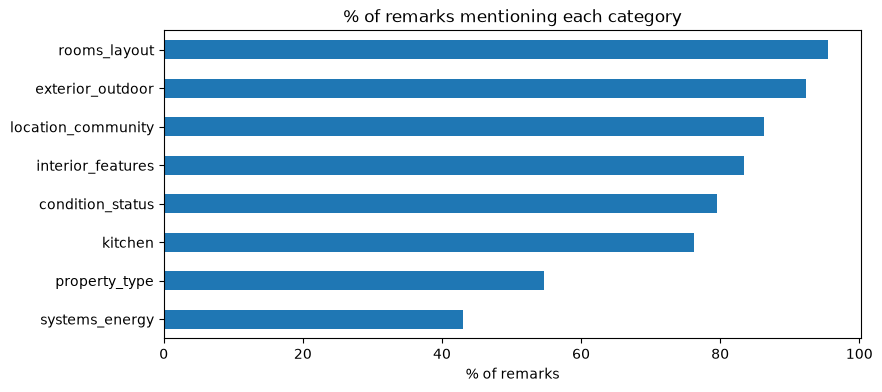

,id,term,category,source,remarks_hit
28,RL_003,bathroom,rooms_layout,ngram,832
27,RL_002,bedroom,rooms_layout,ngram,812
54,K_001,kitchen,kitchen,ngram,725
125,EO_019,garage,exterior_outdoor,ngram,451
109,EO_003,backyard,exterior_outdoor,ngram,426
26,RL_001,primary suite,rooms_layout,ngram,426
176,LC_014,close to shopping,location_community,ngram,381
196,CS_004,updated,condition_status,ngram,380
32,RL_007,living room,rooms_layout,ngram,369
52,RL_027,square feet,rooms_layout,ngram,361


In [9]:
cat_cov = {c: hits_df[th.loc[th.category == c, "id"]].any(axis=1).mean() for c in th["category"].unique()}
pd.Series(cat_cov).mul(100).sort_values().plot.barh()
plt.title("% of remarks mentioning each category")
plt.xlabel("% of remarks")
plt.show()

display(th.sort_values("remarks_hit", ascending=False).head(20))

In [10]:
unused = th[th.remarks_hit == 0]
print(f"{len(unused)} of {len(th)} terms never appear in this sample")
display(unused.groupby(["category", "source"]).size().rename("unused_terms").to_frame())

1 of 218 terms never appear in this sample


,,unused_terms
category,source,
systems_energy,domain,1


**Findings:**
- _TODO: overall coverage %, strongest/weakest categories, do the "domain" terms appear less than "ngram" terms?_

## Data quality checks

In [11]:
quality = pd.Series({
    "duplicate remarks": df["remarks"].duplicated().sum(),
    "leftover '\\r' or '\\n' text": r.str.contains(r"\\[rn]").sum(),
    "non-ASCII characters": r.str.contains(r"[^\x00-\x7F]").sum(),
    "contains a URL": r.str.contains(r"http|www\.", case=False).sum(),
    "contains a phone number": r.str.contains(r"\(?\d{3}\)?[-.\s]\d{3}[-.\s]\d{4}").sum(),
    "contains an email": r.str.contains(r"[\w.]+@[\w.]+\.\w+").sum(),
})
display(quality.rename("remarks").to_frame())

,remarks
duplicate remarks,0
leftover '\r' or '\n' text,0
non-ASCII characters,345
contains a URL,5
contains a phone number,2
contains an email,1


**Findings:**
-  the `\r\r\n` artifacts cleaned in `data_loading.py`